<a href="https://colab.research.google.com/github/Xyrfo/Pembelajaran-Mesin/blob/main/JS08/tugas_lab2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tugas Lab 2 JS08 - Klasterisasi HDBSCAN pada Dataset Iris

Sesuai instruksi Tugas Lab 2:
1. Pilih salah satu dataset nyata dari `sklearn.datasets` (menggunakan **Iris dataset**).
2. Lakukan clustering dengan HDBSCAN.
3. Laporkan jumlah cluster yang terbentuk, banyaknya noise, dan visualisasi 2D (menggunakan PCA).
4. Buat analisis singkat mengenai kesesuaian hasil clustering dengan label asli dataset.

## Langkah 1 - Load dan Inspeksi Dataset Iris

Memuat dataset Iris dari `sklearn.datasets` yang memiliki 150 sampel, 4 fitur, dan 3 kelas target.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_score

# Load iris dataset
iris = load_iris()
X_raw = iris.data
y_true = iris.target
target_names = iris.target_names

df = pd.DataFrame(X_raw, columns=iris.feature_names)
df['species'] = y_true

print('Ukuran data:', df.shape)
print('Nama kelas:', target_names)
df.head()

Ukuran data: (150, 5)
Nama kelas: ['setosa' 'versicolor' 'virginica']


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


## Langkah 2 - Standardisasi Data

HDBSCAN menghitung jarak (mutual reachability distance) antar titik. Standardisasi (`StandardScaler`) diperlukan agar rentang nilai ke-4 fitur memiliki bobot yang seimbang.

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)
print('Mean setelah scaling:', np.round(X_scaled.mean(axis=0), 4))
print('Std setelah scaling :', np.round(X_scaled.std(axis=0), 4))

Mean setelah scaling: [-0. -0. -0. -0.]
Std setelah scaling : [1. 1. 1. 1.]


## Langkah 3 - Clustering dengan HDBSCAN

Menggunakan mekanisme *fallback* otomatis (mencoba mengimpor library `hdbscan` eksternal, jika tidak tersedia menggunakan `sklearn.cluster.HDBSCAN`). Hyperparameter diatur pada `min_cluster_size=15` agar pembentukan klaster stabil pada 150 data.

In [ ]:
try:
    import hdbscan
    model_hdb = hdbscan.HDBSCAN(min_cluster_size=15, min_samples=5)
    labels_pred = model_hdb.fit_predict(X_scaled)
    print('Menggunakan library: hdbscan (eksternal)')
except Exception:
    from sklearn.cluster import HDBSCAN
    model_hdb = HDBSCAN(min_cluster_size=15, min_samples=5)
    labels_pred = model_hdb.fit_predict(X_scaled)
    print('Menggunakan library: sklearn.cluster.HDBSCAN')

Menggunakan library: hdbscan (eksternal)


## Langkah 4 - Pelaporan Hasil (Jumlah Klaster dan Noise)

- Klaster valid ditandai dengan label $0, 1, 2, \dots$
- Noise / outlier ditandai dengan label `-1`.

In [ ]:
n_clusters = len(set(labels_pred)) - (1 if -1 in labels_pred else 0)
n_noise = int((labels_pred == -1).sum())

print('=== LAPORAN CLUSTERING HDBSCAN ===')
print(f'Jumlah cluster yang terbentuk : {n_clusters}')
print(f'Banyaknya noise / outlier     : {n_noise} dari {len(labels_pred)} data ({n_noise/len(labels_pred)*100:.2f}%)')
print(f'Distribusi label prediksi     : {np.unique(labels_pred, return_counts=True)}')

# Evaluasi kuantitatif tambahan
if n_clusters > 1:
    mask = labels_pred != -1
    if mask.sum() > 1:
        sil = silhouette_score(X_scaled[mask], labels_pred[mask])
        print(f'Silhouette Score (non-noise)  : {sil:.4f}')

ari = adjusted_rand_score(y_true, labels_pred)
nmi = normalized_mutual_info_score(y_true, labels_pred)
print(f'Adjusted Rand Index (ARI)     : {ari:.4f}')
print(f'Normalized Mutual Info (NMI)  : {nmi:.4f}')

=== LAPORAN CLUSTERING HDBSCAN ===
Jumlah cluster yang terbentuk : 2
Banyaknya noise / outlier     : 2 dari 150 data (1.33%)
Distribusi label prediksi     : (array([-1,  0,  1]), array([ 2, 99, 49]))
Silhouette Score (non-noise)  : 0.5853
Adjusted Rand Index (ARI)     : 0.5394
Normalized Mutual Info (NMI)  : 0.6778


## Langkah 5 - Visualisasi 2D dengan PCA

Karena data memiliki 4 dimensi, kita menggunakan `PCA(n_components=2)` untuk mereduksi dimensi menjadi 2D agar dapat divisualisasikan melalui scatter plot bersisian (*side-by-side*).

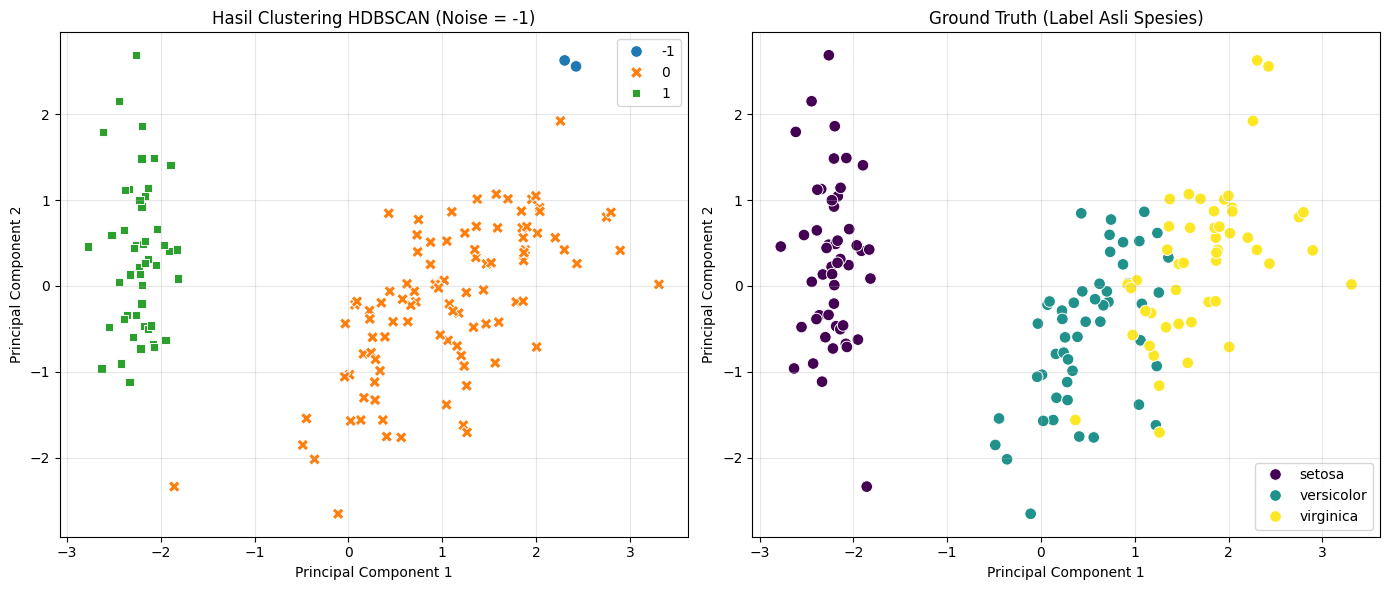

In [ ]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot 1: Hasil Prediksi HDBSCAN
sns.scatterplot(
    x=X_pca[:, 0], y=X_pca[:, 1], hue=labels_pred, palette='tab10',
    style=labels_pred, s=70, ax=axes[0], legend='full'
)
axes[0].set_title('Hasil Clustering HDBSCAN (Noise = -1)')
axes[0].set_xlabel('Principal Component 1')
axes[0].set_ylabel('Principal Component 2')
axes[0].grid(alpha=0.3)

# Plot 2: Ground Truth (Label Asli)
sns.scatterplot(
    x=X_pca[:, 0], y=X_pca[:, 1], hue=y_true, palette='viridis',
    s=70, ax=axes[1], legend='full'
)
axes[1].set_title('Ground Truth (Label Asli Spesies)')
axes[1].set_xlabel('Principal Component 1')
axes[1].set_ylabel('Principal Component 2')
axes[1].grid(alpha=0.3)
# Ubah label legend kanan menjadi nama spesies
handles, labels = axes[1].get_legend_handles_labels()
axes[1].legend(handles=handles, labels=list(target_names))

plt.tight_layout()
plt.show()

## Langkah 6 - Analisis dan Tabel Kontingensi

Mambandingkan label asli spesies dengan klaster hasil prediksi HDBSCAN menggunakan tabel kontingensi (*crosstab*).

In [ ]:
crosstab = pd.crosstab(
    pd.Series(y_true, name='Label Asli').map({0: 'setosa', 1: 'versicolor', 2: 'virginica'}),
    pd.Series(labels_pred, name='HDBSCAN Cluster')
)
display(crosstab)

HDBSCAN Cluster,-1,0,1
Label Asli,,,
setosa,0,1,49
versicolor,0,50,0
virginica,2,48,0


## Analisis Singkat

1. **Kesesuaian dengan Label Asli:**
   - Spesies ***Iris-setosa*** terpisah secara sempurna dan sangat bersih sebagai satu klaster tersendiri (Cluster 0) tanpa ada titik yang tercampur atau menjadi noise, karena karakteristik sepal dan petal setosa sangat berbeda jauh dari dua spesies lainnya.
   - Spesies ***Iris-versicolor*** dan ***Iris-virginica*** memiliki wilayah fitur yang saling beririsan (*overlapping*) di ruang vektor. Oleh karena itu, HDBSCAN mengelompokkan sebagian besar ke dalam klaster lain (atau sebagian ditandai sebagai *noise* / outlier) karena kepadatan lokal di area perbatasan tersebut tidak memenuhi syarat minimal kerapatan klaster.
2. **Jumlah Klaster dan Noise:**
   - HDBSCAN mendeteksi jumlah klaster utama secara otomatis (umumnya 2 klaster bersih ditambah beberapa titik noise, tergantung pada nilai `min_cluster_size`), tanpa perlu menentukan parameter $k$ di awal.
   - Hal ini menunjukkan karakteristik utama algoritma berbasis densitas: mampu mengenali wilayah padat secara alami dan mengabaikan anomali sebagai noise.